# 07 锁定模型的最终测试

固定使用06中20261111_010719_491327这次实验的最佳权重；不重新训练、不选择新参数、不裁剪输出。
目标为封顶AQHI（10+映射为10并保留标记），17个非塔门站点，72小时输入、24小时预测。
测试目标为源日期2025-01-01至2026-06-30；按既定小时规则对应2025-01-01 01:00至2026-07-01 00:00（香港时间）。
滚动预测允许使用起点之前真实已观测到的测试期历史，但所有目标必须处于测试期；标准化只读取训练时保存的参数。
所有模型使用相同完整窗口。首次查看本Notebook成绩之后，这段数据即已用于测试；不得据此调参后仍声称它是未见测试集。


In [1]:
import os
os.environ['MKL_THREADING_LAYER']='SEQUENTIAL'
import torch
from torch import nn
from pathlib import Path
from datetime import datetime
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src/aqhi_data.py').exists(): ROOT=ROOT.parent
MODEL_DIR=ROOT/'data/processed/tsmixer/20261111_010719_491327'
config=json.loads((MODEL_DIR/'model_config.json').read_text(encoding='utf-8'))
SOURCE=Path(config['source'])
STATIONS=config['stations']; L=config['lookback']; H=config['horizon']
assert len(STATIONS)==17 and (L,H)==(72,24)
assert config['blocks']==2 and config['hidden']==32 and config['dropout']==.1
torch.set_num_threads(4); torch.manual_seed(config['seed'])
torch.use_deterministic_algorithms(True)
scaler=np.load(MODEL_DIR/'scaler.npz')
assert scaler['stations'].tolist()==STATIONS
mu,sd=scaler['mean'],scaler['std']
test_boundary=pd.Timestamp(config['validation_end']).tz_convert('Asia/Hong_Kong')
test_end=pd.Timestamp('2026-07-01 00:00',tz='Asia/Hong_Kong')
OUT=ROOT/'data/processed/final_test'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True,exist_ok=False)
lock={'model_directory':str(MODEL_DIR),'model_sha256':hashlib.sha256((MODEL_DIR/'best_model_state.pt').read_bytes()).hexdigest(),
 'scaler_sha256':hashlib.sha256((MODEL_DIR/'scaler.npz').read_bytes()).hexdigest(),
 'test_start_exclusive':str(test_boundary),'test_end_inclusive':str(test_end),
 'retraining':False,'clipping':False,'selection':'fixed before evaluating test',
 'lookback':L,'horizon':H,'stations':STATIONS,'target':config['target']}
(OUT/'evaluation_lock.json').write_text(json.dumps(lock,ensure_ascii=False,indent=2),encoding='utf-8')
print('锁定模型：',MODEL_DIR)
print('输出目录：',OUT)

锁定模型： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\tsmixer\20261111_010719_491327
输出目录： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\final_test\20261111_011923_374913


## 1. 测试窗口
原始缺失保留，仅使用全部输入和目标站点均有封顶值的窗口。报告覆盖率，避免把完整窗口成绩解释成全天候表现。

In [2]:
h=pd.read_csv(SOURCE/'history_all_audited.csv.gz',keep_default_na=False,dtype={'source_date':str})
h=h.loc[h.station_id.isin(STATIONS)].copy()
h['timestamp']=pd.to_datetime(h.timestamp,utc=True).dt.tz_convert('Asia/Hong_Kong')
h=h.loc[h.timestamp.ge(test_boundary-pd.Timedelta(hours=L-1))&h.timestamp.le(test_end)].copy()
for col in ['is_10_plus','is_substituted']:
    if h[col].dtype!=bool:
        assert h[col].astype(str).isin(['True','False']).all()
        h[col]=h[col].astype(str).eq('True')
h['capped_aqhi']=pd.to_numeric(h.aqhi_value,errors='coerce')
h.loc[h.is_10_plus,'capped_aqhi']=10.0
assert not h.duplicated(['timestamp','station_id']).any()
index=pd.date_range(test_boundary-pd.Timedelta(hours=L-1),test_end,freq='h')
panel=h.pivot(index='timestamp',columns='station_id',values='capped_aqhi').reindex(index=index,columns=STATIONS)
cap=h.pivot(index='timestamp',columns='station_id',values='is_10_plus').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
arr=panel.to_numpy(dtype=float)
present=pd.Series(np.isfinite(arr).all(axis=1),index=index)
valid=present.astype(int).rolling(L).sum().shift(1).eq(L)&present.astype(int).rolling(H).sum().shift(-(H-1)).eq(H)
in_test=(index>test_boundary)&((index+pd.Timedelta(hours=H-1))<=test_end)
origins=np.flatnonzero(valid.to_numpy()&in_test)
assert len(origins)>0 and origins.min()>=L
ti=origins[:,None]+np.arange(H)
assert index[ti.min()]>test_boundary and index[ti.max()]<=test_end
y=arr[ti]; ycap=cap.to_numpy()[ti]
assert np.isfinite(y).all()
coverage={'candidate_origins':int(in_test.sum()),'usable_origins':len(origins),
 'usable_origin_fraction':float(len(origins)/in_test.sum()),'unique_target_station_hours':int(len(np.unique(ti))*len(STATIONS))}
print(coverage)
pd.DataFrame({'forecast_start':index[origins]}).to_csv(OUT/'test_origins.csv',index=False)
(OUT/'coverage.json').write_text(json.dumps(coverage,indent=2),encoding='utf-8')

{'candidate_origins': 13081, 'usable_origins': 12450, 'usable_origin_fraction': 0.9517620976989527, 'unique_target_station_hours': 213996}


148

## 2. 载入权重，仅推理
网络结构与06完全一致，严格加载权重；不创建优化器。

In [3]:
class MixerBlock(nn.Module):
    def __init__(self,length,features,hidden=32,dropout=.1):
        super().__init__()
        self.time_norm=nn.LayerNorm((length,features))
        self.time_linear=nn.Linear(length,length)
        self.dropout=nn.Dropout(dropout)
        self.feature_norm=nn.LayerNorm((length,features))
        self.feature_mlp=nn.Sequential(nn.Linear(features,hidden),nn.ReLU(),
            nn.Dropout(dropout),nn.Linear(hidden,features),nn.Dropout(dropout))
    def forward(self,x):
        t=self.time_norm(x).transpose(1,2)
        x=x+self.dropout(torch.relu(self.time_linear(t)).transpose(1,2))
        return x+self.feature_mlp(self.feature_norm(x))
class TSMixer(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks=nn.Sequential(MixerBlock(L,len(STATIONS)),MixerBlock(L,len(STATIONS)))
        self.projection=nn.Linear(L,H)
    def forward(self,x):
        return self.projection(self.blocks(x).transpose(1,2)).transpose(1,2)

model=TSMixer()
model.load_state_dict(torch.load(MODEL_DIR/'best_model_state.pt',map_location='cpu',weights_only=True),strict=True)
model.eval()
scaled=((arr-mu)/sd).astype('float32')
chunks=[]
with torch.inference_mode():
    for start in range(0,len(origins),512):
        positions=origins[start:start+512]
        batch=np.stack([scaled[t-L:t] for t in positions])
        assert np.isfinite(batch).all()
        chunks.append(model(torch.from_numpy(batch)).numpy())
prediction=np.concatenate(chunks)*sd+mu
assert prediction.shape==y.shape and np.isfinite(prediction).all()
assert (ti-24<origins[:,None]).all()
predictions={'Persistence':np.repeat(arr[origins-1,None,:],H,axis=1),
 'Previous day':arr[ti-24],'TSMixer':prediction}
assert hashlib.sha256((MODEL_DIR/'best_model_state.pt').read_bytes()).hexdigest()==lock['model_sha256']
print('推理完成；权重校验未改变。')

推理完成；权重校验未改变。


## 3. 最终测试指标

MAE/RMSE越低越好；bias为预测减目标。指标按预测起点×预测时长×站点汇总，重叠预测并非独立观测。
原始10+的误差仅针对封顶值10。高值子集另外列出不重复的站点小时数，不能据少量极端事件作稳健性结论。


In [4]:
def metric(a,b):
    e=b-a
    return {'n_forecasts':int(e.size),'MAE':float(np.abs(e).mean()) if e.size else None,
      'RMSE':float(np.sqrt(np.square(e).mean())) if e.size else None,'bias':float(e.mean()) if e.size else None}
overall=[]; subsets=[]; station=[]; horizon=[]; monthly=[]
unique=np.unique(ti)
for name,p in predictions.items():
    overall.append({'model':name,**metric(y,p)})
    for label,mask,count in [('target_at_least_7',y>=7,int((arr[unique]>=7).sum())),
       ('original_10_plus',ycap,int(cap.to_numpy()[unique].sum()))]:
        subsets.append({'model':name,'subset':label,'unique_station_hours':count,**metric(y[mask],p[mask])})
    for j,s in enumerate(STATIONS):station.append({'model':name,'station_id':s,**metric(y[:,:,j],p[:,:,j])})
    for j in range(H):horizon.append({'model':name,'horizon':j+1,**metric(y[:,j,:],p[:,j,:])})
    for month in sorted(set(index[origins].strftime('%Y-%m'))):
        mask=index[origins].strftime('%Y-%m')==month
        monthly.append({'model':name,'forecast_start_month':month,**metric(y[mask],p[mask])})
overall=pd.DataFrame(overall); subsets=pd.DataFrame(subsets)
display(overall.round(4));display(subsets.round(4))
baseline=overall.set_index('model').loc['Previous day']
mixer=overall.set_index('model').loc['TSMixer']
print('相对前一天基准MAE改善百分比（负值表示变差）：',100*(1-mixer.MAE/baseline.MAE))
print('预测超出1–10范围的比例：',float(((prediction<1)|(prediction>10)).mean()))

,model,n_forecasts,MAE,RMSE,bias
0,Persistence,5079600,0.6225,0.9971,0.0027
1,Previous day,5079600,0.6219,0.9702,0.0060
2,TSMixer,5079600,0.5383,0.7509,-0.0671


,model,subset,unique_station_hours,n_forecasts,MAE,RMSE,bias
0,Persistence,target_at_least_7,2976,71003,2.4295,2.9782,-2.1740
1,Persistence,original_10_plus,55,1320,2.8591,3.3925,-2.8591
2,Previous day,target_at_least_7,2976,71003,2.3969,2.9339,-2.0710
3,Previous day,original_10_plus,55,1320,2.5636,2.8572,-2.5636
4,TSMixer,target_at_least_7,2976,71003,2.3569,2.7639,-2.3428
5,TSMixer,original_10_plus,55,1320,4.2926,4.4720,-4.2926


相对前一天基准MAE改善百分比（负值表示变差）： 13.433155641689009
预测超出1–10范围的比例： 2.027718718009292e-05


## 4. 保存测试结果
无论成绩如何都保留。后续产品可以选择基准或模型，但不能根据本次测试反复调参并继续把它称为未见测试集。

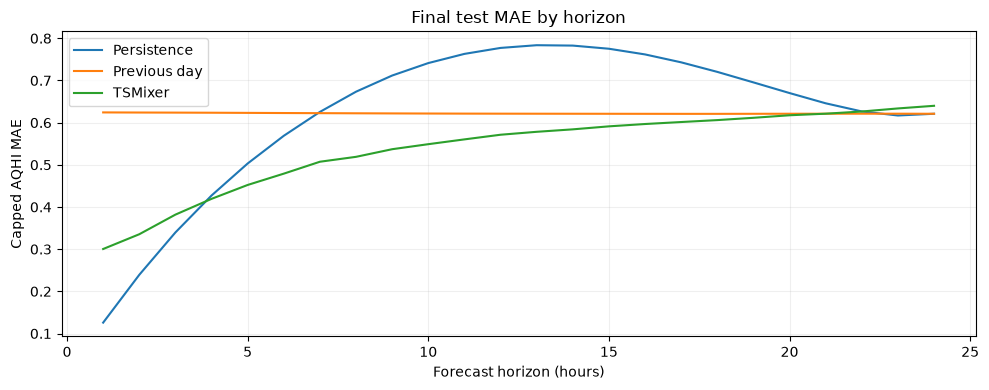

最终测试结果已保存： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\final_test\20261111_011923_374913
本次未训练、未调参、未修改模型或标准化参数。


In [5]:
hz=pd.DataFrame(horizon)
fig,ax=plt.subplots(figsize=(10,4))
for name,g in hz.groupby('model'):ax.plot(g.horizon,g.MAE,label=name)
ax.set(title='Final test MAE by horizon',xlabel='Forecast horizon (hours)',ylabel='Capped AQHI MAE')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'test_mae_by_horizon.png',dpi=150);plt.show()
for name,table in {'overall_test':overall,'subset_test':subsets,'station_test':pd.DataFrame(station),
 'horizon_test':hz,'monthly_test':pd.DataFrame(monthly)}.items():
    table.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')
print('最终测试结果已保存：',OUT)
print('本次未训练、未调参、未修改模型或标准化参数。')